## ML Lab 8
### Ishika Sahare

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("ai4i2020.csv")

In [3]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [5]:
df.shape

(10000, 14)

In [6]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [7]:
df.dtypes

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [9]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [10]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df["Type"].unique()

array(['M', 'L', 'H'], dtype=object)

In [13]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

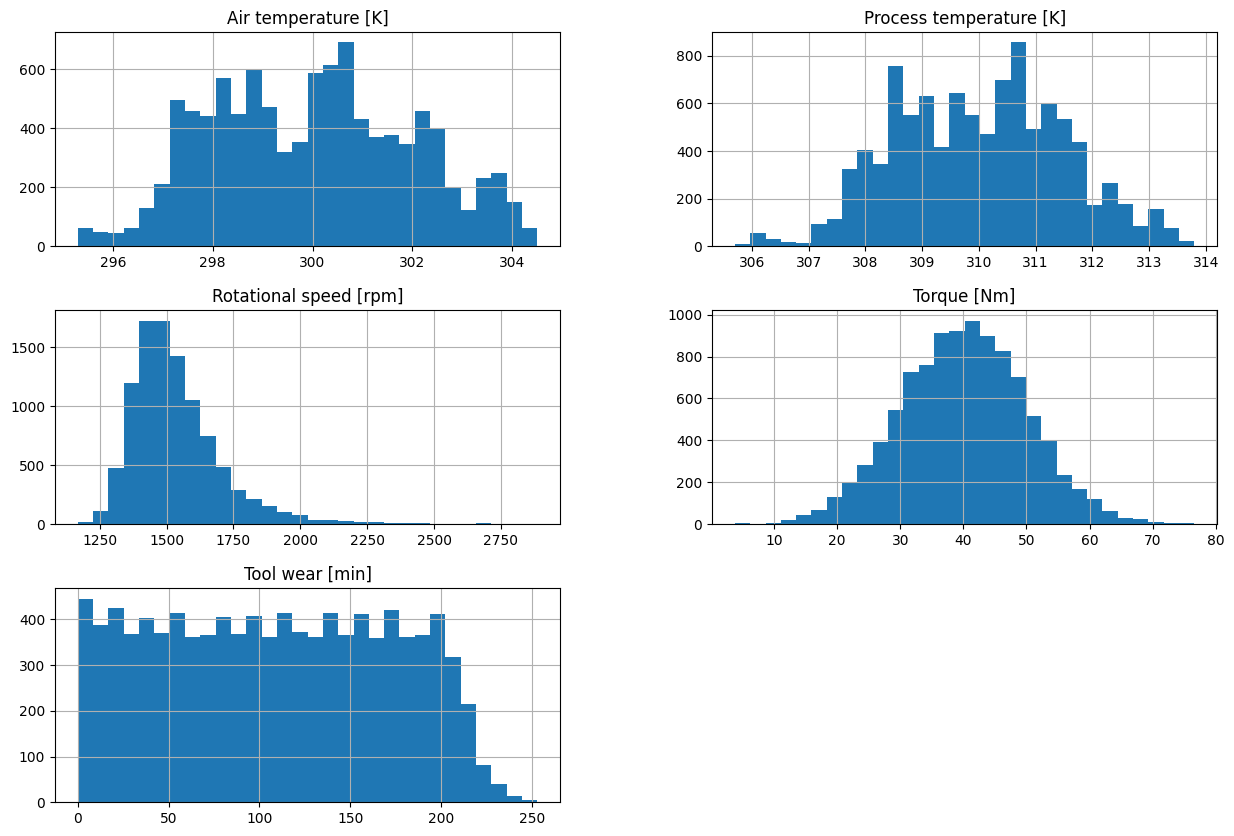

In [14]:
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[numerical_features].hist(figsize=(15, 10), bins=30)
plt.show()

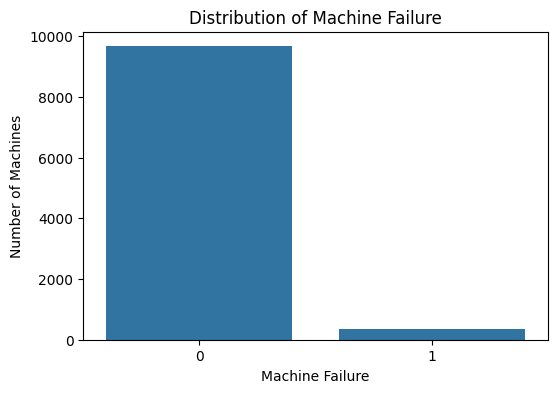

In [15]:
plt.figure(figsize=(6,4))
sns.countplot(x="Machine failure", data=df)

plt.title("Distribution of Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Machines")
plt.show()

In [16]:
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]


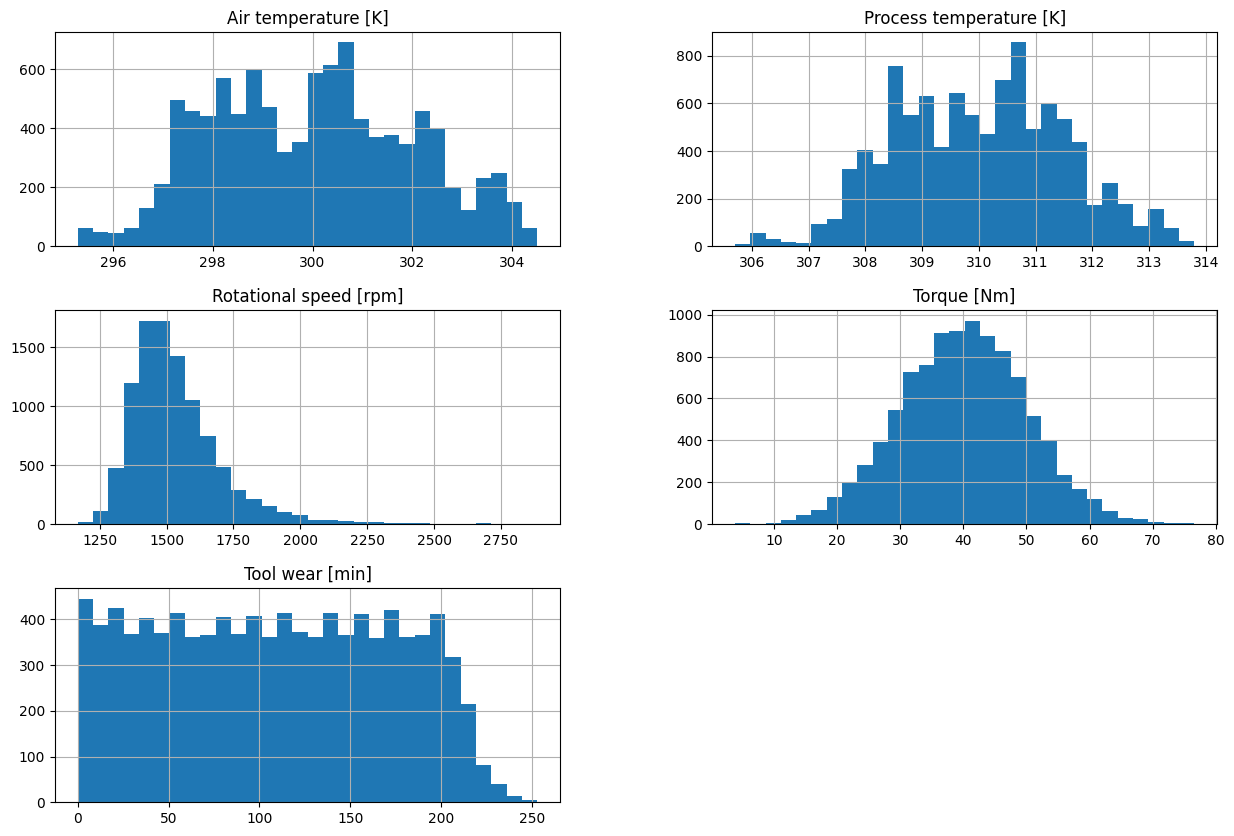

In [17]:
df[numerical_features].hist(figsize=(15, 10), bins=30)
plt.show()


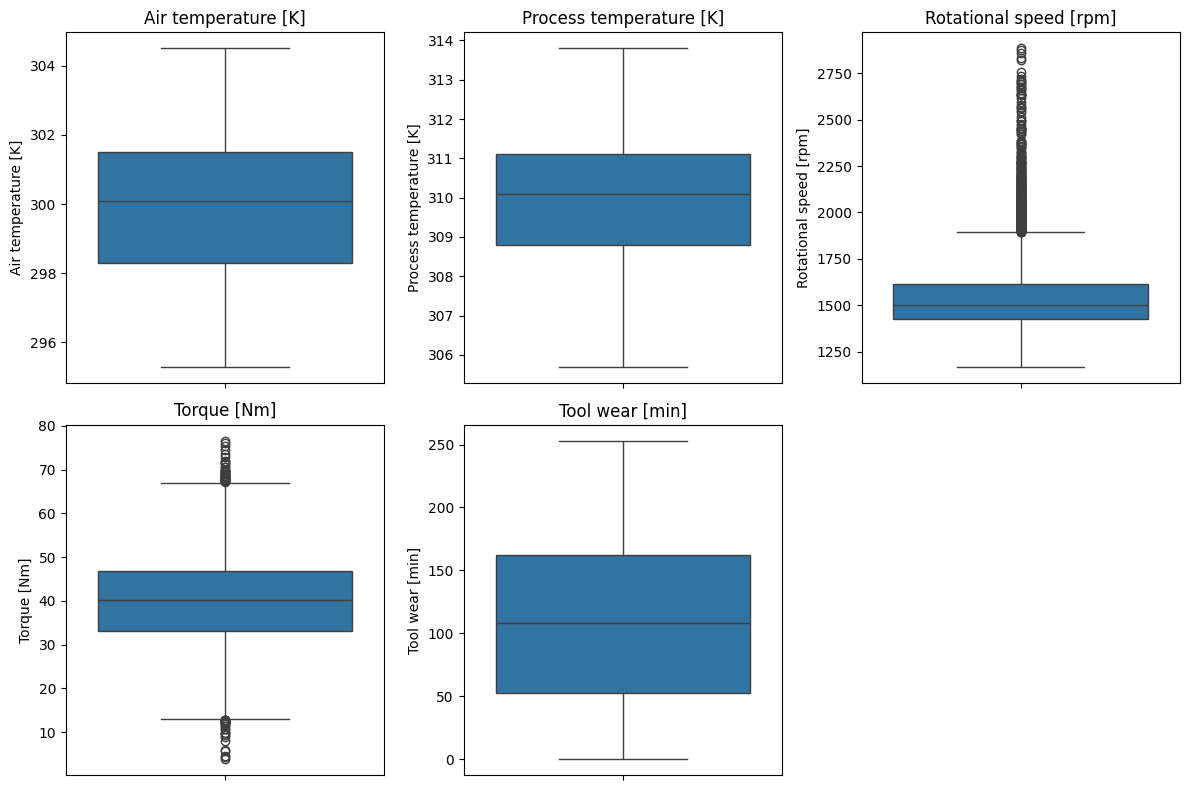

In [18]:
plt.figure(figsize=(12,8))

for i, column in enumerate(numerical_features,1):
    plt.subplot(2,3,i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

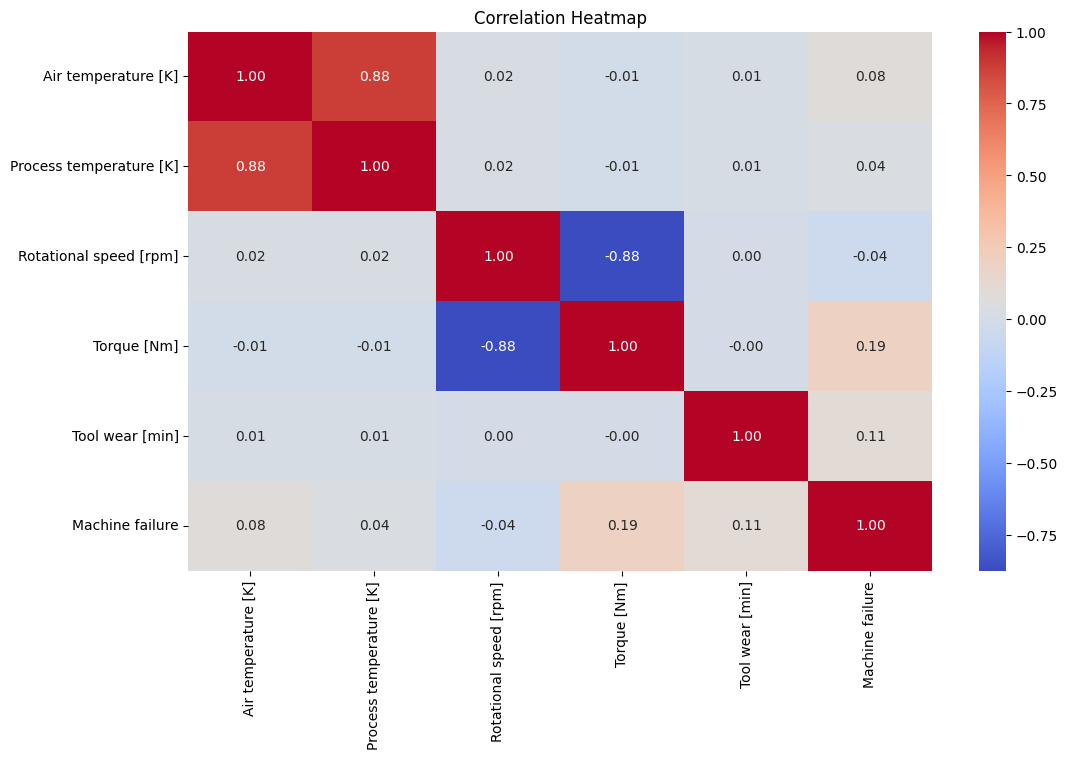

In [19]:
plt.figure(figsize=(12,7))
correlation = df[numerical_features + ["Machine failure"]].corr()
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

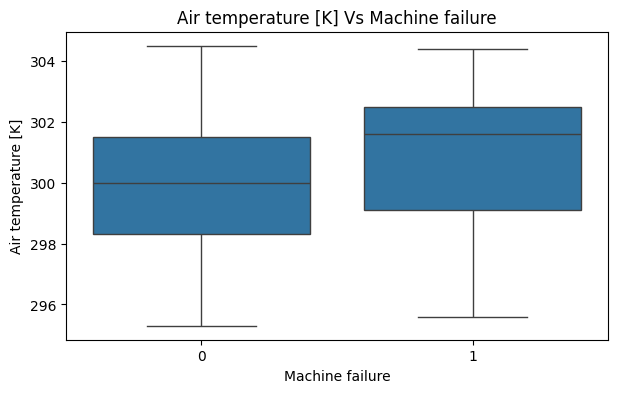

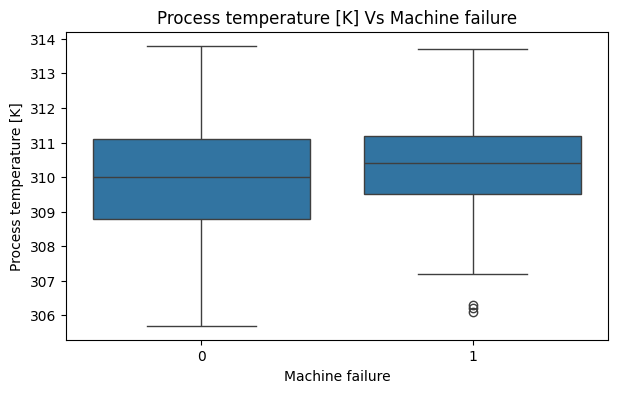

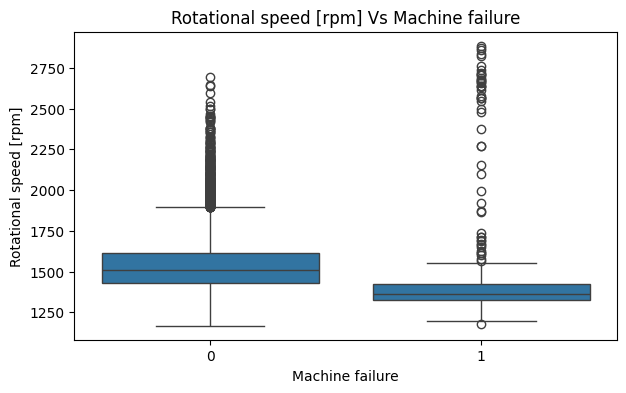

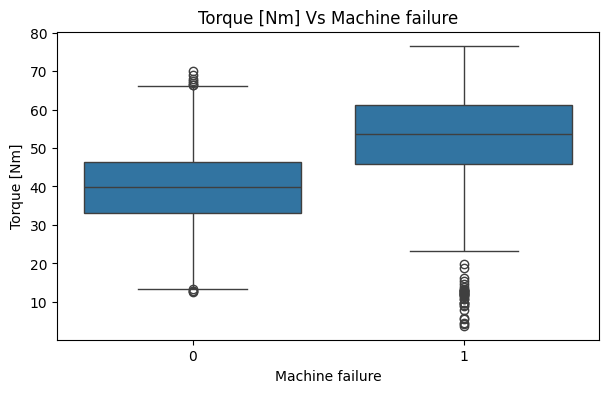

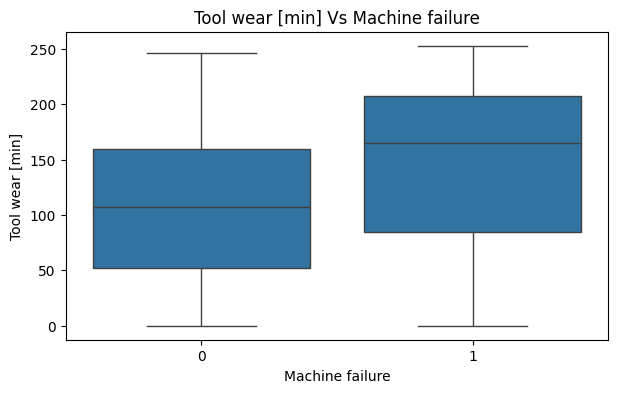

In [20]:
for column in numerical_features:
  plt.figure(figsize=(7,4))
  sns.boxplot(x="Machine failure", y=column, data=df)
  plt.title(f"{column} Vs Machine failure")
  plt.show()

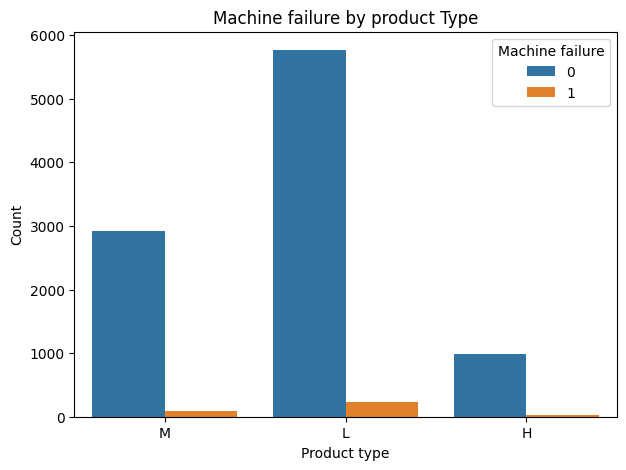

In [21]:
plt.figure(figsize=(7,5))
sns.countplot(x="Type",hue="Machine failure",data=df)
plt.title("Machine failure by product Type")
plt.xlabel("Product type")
plt.ylabel("Count")
plt.show()

In [22]:
X= df[
    [
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]",
        "Type"
]
]

In [23]:
y=df["Machine failure"]

In [24]:
print("Input shape",X.shape)
print("Output shape",y.shape)

Input shape (10000, 6)
Output shape (10000,)


In [25]:
categorical_features =["Type"]
numerical_features =[
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 8000
Testing samples: 2000


In [27]:
processor = ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numerical_features),
        ("cat",OneHotEncoder(handle_unknown='ignore'),categorical_features)
    ]
)

In [28]:
linear_svm = Pipeline(
    steps=[("preprocessor", processor), ("classifier", SVC(kernel="linear"))]
)
linear_svm.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [29]:
y_pred_linear = linear_svm.predict(X_test)

In [30]:
accuracy_linear = accuracy_score(y_test, y_pred_linear)
precision_linear = precision_score(y_test, y_pred_linear)
recall_linear = recall_score(y_test, y_pred_linear)
f1_linear = f1_score(y_test, y_pred_linear)

print("Accuracy:", accuracy_linear)
print("Precision:", precision_linear)
print("Recall:", recall_linear)
print("F1 Score:", f1_linear)

Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [31]:
print(
    classification_report(
        y_test,
        y_pred_linear,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



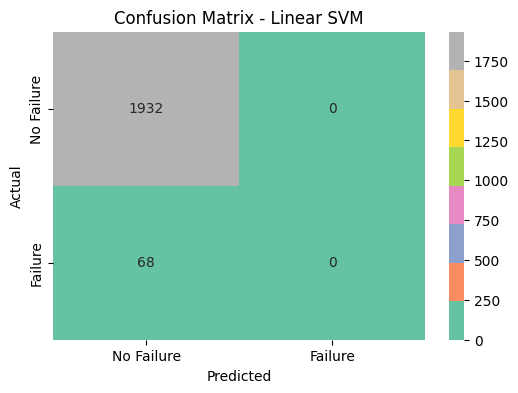

In [32]:
cm_linear = confusion_matrix(y_test, y_pred_linear)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_linear, annot=True, fmt="d", cmap="Set2",
            xticklabels=["No Failure","Failure"],
            yticklabels=["No Failure","Failure"]
            )
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Linear SVM")
plt.show()

In [33]:
rbf_svm = Pipeline(
    steps=[("preprocessor", processor), ("classifier", SVC(kernel="rbf"))]
)
rbf_svm.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [34]:
y_pred_rbf = rbf_svm.predict(X_test)

In [35]:
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test, y_pred_rbf)
recall_rbf = recall_score(y_test, y_pred_rbf)
f1_rbf = f1_score(y_test, y_pred_rbf)

print("RBF SVM Results")
print("Accuracy:", accuracy_rbf)
print("Precision:", precision_rbf)
print("Recall:", recall_rbf)
print("F1 Score:", f1_rbf)

RBF SVM Results
Accuracy: 0.972
Precision: 0.875
Recall: 0.20588235294117646
F1 Score: 0.3333333333333333


In [36]:
print(classification_report(y_test,y_pred_rbf,target_names= ["No Failure","Failure"],zero_division=0))

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.99      1932
     Failure       0.88      0.21      0.33        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.66      2000
weighted avg       0.97      0.97      0.96      2000



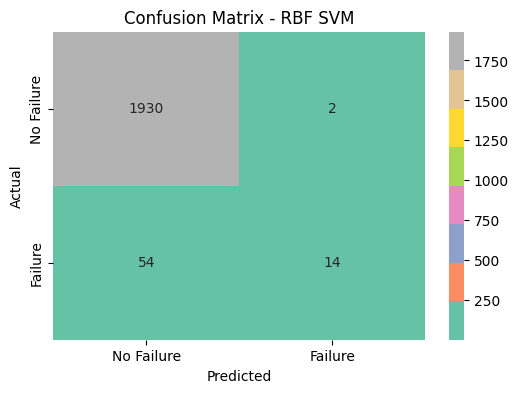

In [37]:
cm_rbf = confusion_matrix(y_test, y_pred_rbf)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rbf, annot=True, fmt="d", cmap="Set2",
            xticklabels=["No Failure","Failure"],
            yticklabels=["No Failure","Failure"]
            )
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - RBF SVM")
plt.show()

In [38]:
comparison =pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM"],
    "Accuracy": [accuracy_linear, accuracy_rbf],
    "Precision": [precision_linear, precision_rbf],
    "Recall": [recall_linear, recall_rbf],
    "F1 Score": [f1_linear, f1_rbf]
})
comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.966,0.000,0.000000,0.000000
1,RBF SVM,0.972,0.875,0.205882,0.333333


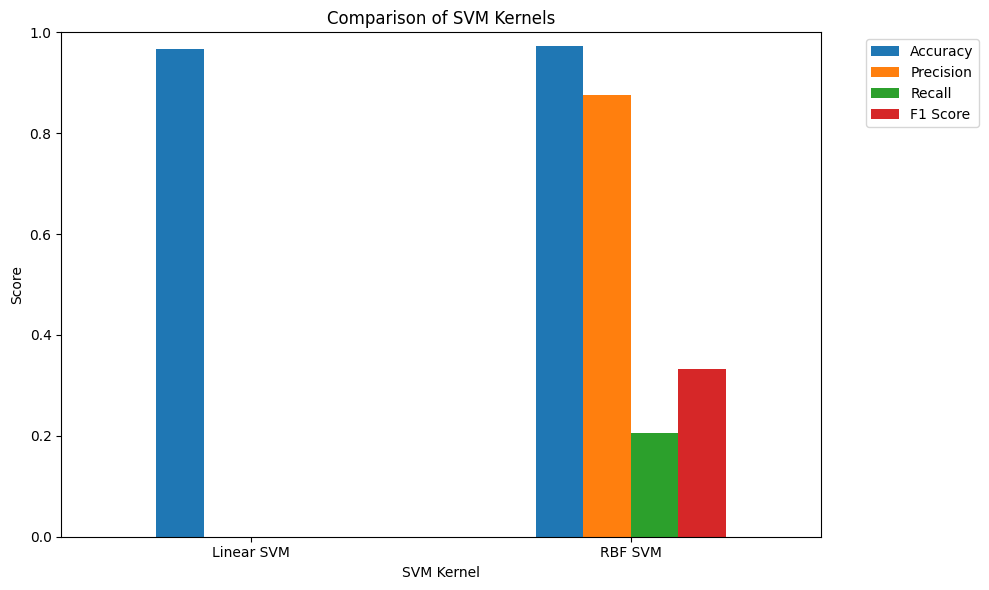

In [39]:
comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10,6)
)
plt.title("Comparison of SVM Kernels")
plt.xlabel("SVM Kernel")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [40]:
from sklearn.pipeline import Pipeline
pipeline = Pipeline(
    steps=[
        ("preprocessor", processor),
        ("classifier", SVC())
    ]
)

In [41]:
param_grid =[{"classifier_kernel":["linear"],"classifier__C": [0.1,1,10,100]},
             {"classifier__Kernel":["rbf"],"classifier__C": [0.1,1,10,100],"classifier__gamma": ["scaled",0.01,0.1,1]}
             ]

In [42]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

In [46]:

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

# Create pipeline
pipeline = Pipeline([
    ("preprocessor", processor),
    ("classifier", SVC())
])

# Correct parameter grid
param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10, 100]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", 0.01, 0.1, 1]
    }
]

# GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Train and tune the model
grid_search.fit(X_train, y_train)

print("GridSearchCV completed successfully!")
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1 Score:", grid_search.best_score_)


Fitting 5 folds for each of 20 candidates, totalling 100 fits
GridSearchCV completed successfully!
Best Parameters: {'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
Best Cross-Validation F1 Score: 0.7080372186703207


In [47]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}


In [48]:
print("Best Cross-Validation F1 Score:",grid_search.best_score_)

Best Cross-Validation F1 Score: 0.7080372186703207


In [49]:
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)

In [50]:
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_score = f1_score(y_test, y_pred_tuned)

print("Tuned Model Results")
print("Accuracy:", accuracy_tuned)
print("Precision:", precision_tuned)
print("Recall:", recall_tuned)
print("F1 Score:", f1_score)


Tuned Model Results
Accuracy: 0.98
Precision: 0.7592592592592593
Recall: 0.6029411764705882
F1 Score: 0.6721311475409836


In [53]:

final_comparison = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM", "Tuned SVM"],
    "Accuracy": [accuracy_linear, accuracy_rbf, accuracy_tuned],
    "Precision": [precision_linear, precision_rbf, precision_tuned],
    "Recall": [recall_linear, recall_rbf, recall_tuned]
})

final_comparison

,Model,Accuracy,Precision,Recall
0,Linear SVM,0.966,0.000000,0.000000
1,RBF SVM,0.972,0.875000,0.205882
2,Tuned SVM,0.980,0.759259,0.602941


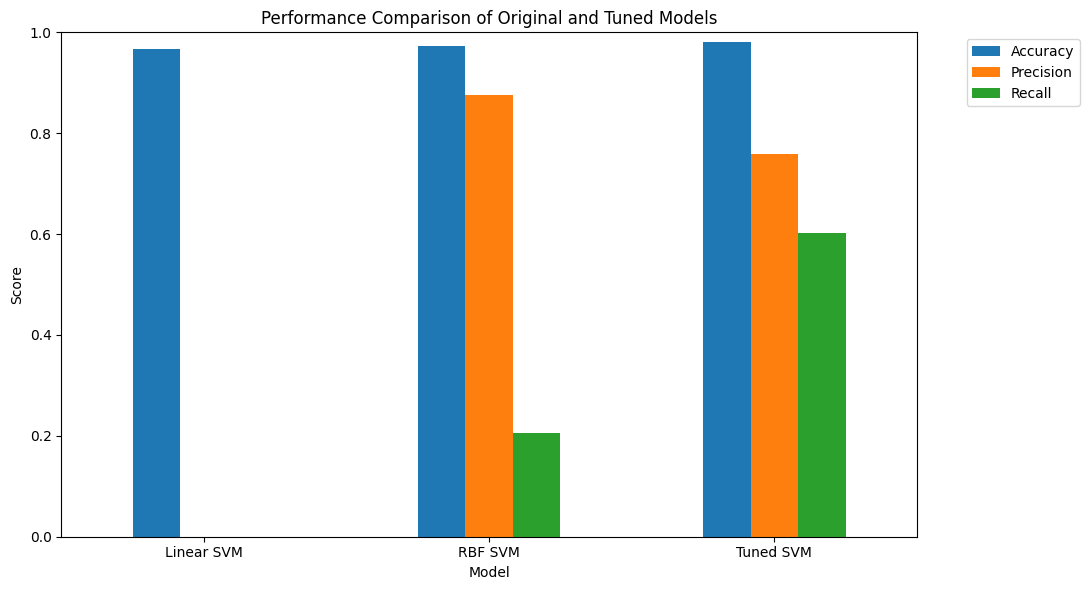

In [55]:

import matplotlib.pyplot as plt

final_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Performance Comparison of Original and Tuned Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()